# Titanic Prediction Project

## Imports

In [67]:
import matplotlib.pyplot as plt
import numpy
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
  accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

## Load Dataset

In [68]:
titanic_df = pd.read_csv("../data/titanic_passengers.csv")
display(titanic_df.head())
display(titanic_df.tail())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [69]:
print("Shape: ", titanic_df.shape)

Shape:  (891, 12)


In [70]:
display(titanic_df.info())
display(titanic_df.columns)
display(titanic_df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


None

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

There are 891 passenger entries in this dataset, we are going to use [Survived] column as the target. Age has 177 missing values (Which could be valuable to survival), Cabin has 687 missing values, and Embarked has 2 missing values. Name, Sex, Ticket, Cabin, and Embarked are catergorical features.

# Corrections to DataFrame
Drop cabin because it has to many missing values, Drop name and ticket because it adding little to nothing to this research, fill missing ages with median age, fill missing embarked values, and convert sex and embarked to numeric values


In [71]:
titanic_df = titanic_df.drop(columns=["Cabin", "Name", "Ticket"])


titanic_df["Age"] = titanic_df["Age"].fillna(
  titanic_df["Age"].median()
)

titanic_df["Embarked"] = titanic_df["Embarked"].fillna(
  titanic_df["Embarked"].mode()[0]
)

titanic_df["Sex"] = titanic_df["Sex"].map({
    "male": 0,
    "female": 1
})

titanic_df["Embarked"] = titanic_df["Embarked"].map({
    "S": 0,
    "C": 1,
    "Q": 2
})

# EDA

Survival distribution, survival by gender, survival by passenger class, Age distibution, and Correlation Matrix.
0 = No, 1 = Yes

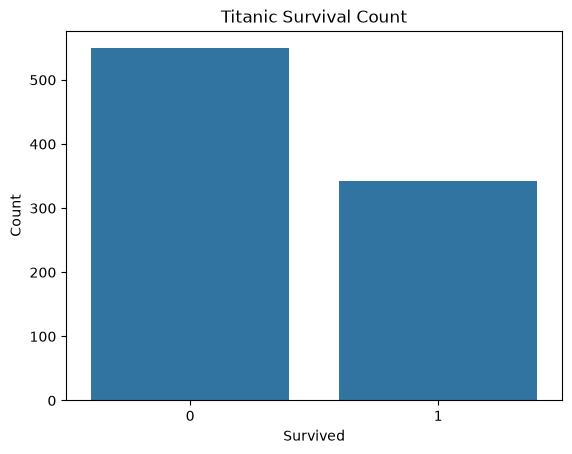

In [72]:
sns.countplot(data=titanic_df, x="Survived")

plt.title("Titanic Survival Count")
plt.xlabel("Survived")
plt.ylabel("Count")

plt.show()

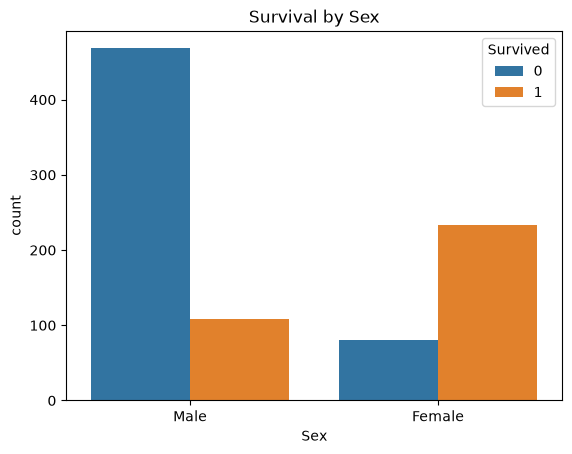

In [73]:
sns.countplot(
    data=titanic_df,
    x="Sex",
    hue="Survived"
)

plt.title("Survival by Sex")
plt.xticks([0, 1], ["Male", "Female"])

plt.show()

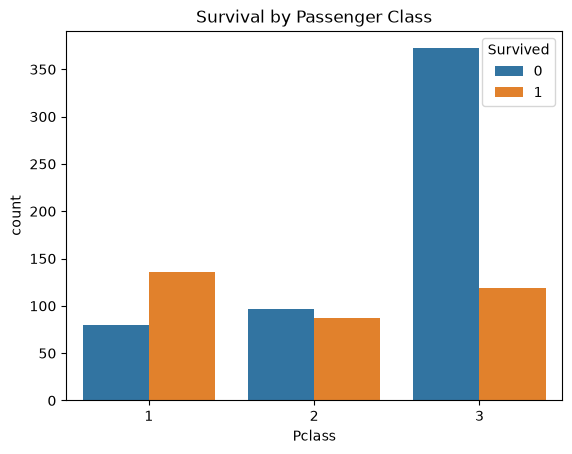

In [74]:
sns.countplot(
    data=titanic_df,
    x="Pclass",
    hue="Survived"
)

plt.title("Survival by Passenger Class")

plt.show()

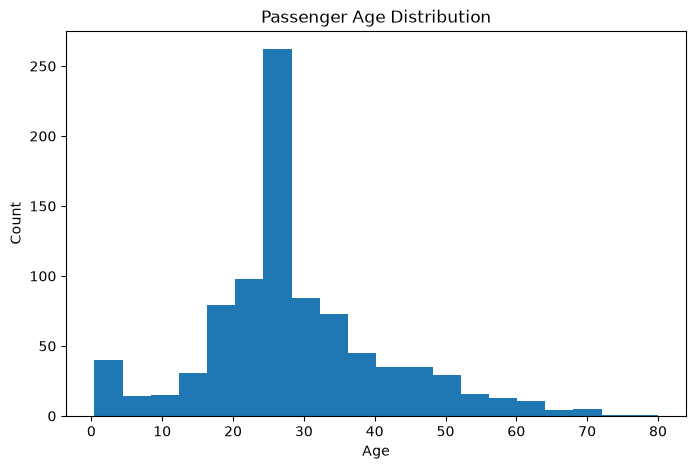

In [75]:
plt.figure(figsize=(8, 5))

plt.hist(titanic_df["Age"], bins=20)

plt.title("Passenger Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")

plt.show()

Note that this distibution may be different than actual, 177 values were changed to the median age to fill missing values.

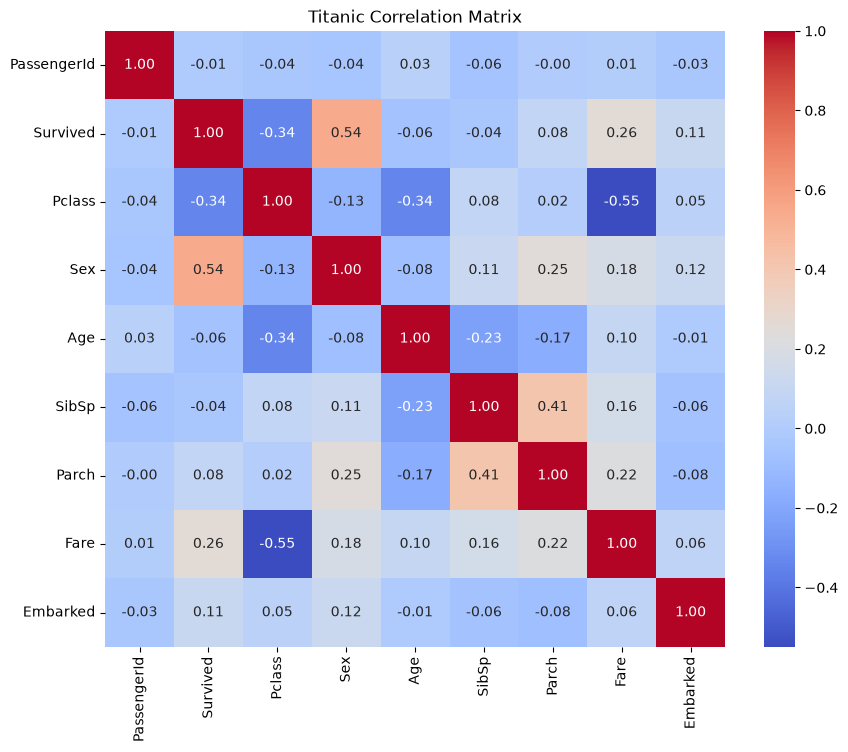

In [76]:
corr_matrix = titanic_df.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Titanic Correlation Matrix")

plt.show()

# First Model
(KNN)

In [77]:
X = titanic_df.drop(columns=["Survived"])
y = titanic_df["Survived"]

print(X.shape)
print(y.shape)

(891, 8)
(891,)


In [78]:
selector = SelectKBest(score_func=chi2, k="all")

selector.fit(X, y)

scores = pd.DataFrame({
    "Feature": X.columns,
    "Score": selector.scores_
})

scores = scores.sort_values(
    by="Score",
    ascending=False
)

print(scores)

       Feature        Score
6         Fare  4518.319091
2          Sex   170.348127
1       Pclass    30.873699
3          Age    21.649163
7     Embarked    11.353117
5        Parch    10.097499
0  PassengerId     3.312934
4        SibSp     2.581865


Train/Test Split

In [79]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=123321
)

print(X_train.shape)
print(X_test.shape)

(668, 8)
(223, 8)


KNN

In [80]:
knn = KNeighborsClassifier()

knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


# Evaluate

In [81]:
train_score = knn.score(X_train, y_train)
test_score = knn.score(X_test, y_test)

print("Train Score:", train_score)
print("Test Score:", test_score)

Train Score: 0.7335329341317365
Test Score: 0.6367713004484304


Classification Report

In [82]:
y_pred = knn.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.64      0.88      0.74       130
           1       0.64      0.29      0.40        93

    accuracy                           0.64       223
   macro avg       0.64      0.59      0.57       223
weighted avg       0.64      0.64      0.60       223



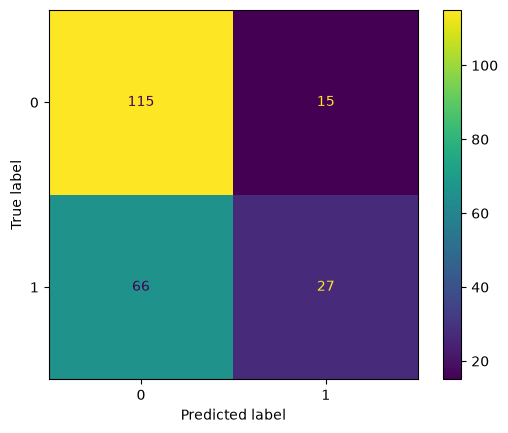

In [83]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.show()